# 06 · OSDR EDA: understand ISS cabin air

**Questions**
1. What unit is CO2 in, and how often is it sampled? (Both were "not confirmed" in `docs/DATASETS.md`.)
2. How does the ISS cabin differ from the ground control: CO2, temperature, humidity?
3. How does cabin CO2 behave in time (daily profile, memory), and how often is it above 3 mmHg (1-hour mean) and 2.5 mmHg (7-day mean)?
4. How are temperature, humidity and CO2 related?
5. ISS radiation: galactic cosmic rays (GCR) vs South Atlantic Anomaly (SAA), and how does it compare with the Mars surface?

**Inputs:** `data/raw/osdr_eda/*_telemetry.csv`, `*_radiation.csv` (real ISS data, NASA OSDR Environmental Data App).
**Outputs:** `data/processed/iss_cabin.parquet` (hourly), `data/processed/iss_radiation_daily.parquet`, figures `reports/figures/06_*.png`.

In [1]:
import sys
sys.path.insert(0, "../ml")
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import acf
from sol_ml.nbutil import *
from sol_ml.data import osdr_eda
from sol_ml.detectors import cabin as gate

rng = setup()
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore")

cabin = osdr_eda.load_telemetry()
hourly = osdr_eda.to_hourly(cabin)
dose = osdr_eda.load_radiation()
hourly.to_parquet(PROCESSED / "iss_cabin.parquet", index=False)
dose.to_parquet(PROCESSED / "iss_radiation_daily.parquet", index=False)
print(len(cabin), "telemetry rows in", cabin.mission.nunique(), "missions ->", len(hourly), "hourly rows |", len(dose), "radiation days in", dose.mission.nunique(), "missions")
cabin.head(3)

536930 telemetry rows in 14 missions -> 24446 hourly rows | 467 radiation days in 11 missions


,mission,time,temperature_iss,temperature_ground,humidity_iss,humidity_ground,co2_iss,co2_ground,co2_mmhg
0,RR-10,2020-12-04 07:30:00,23.7,22.6,34.0,31.0,NaN,NaN,NaN
1,RR-10,2020-12-04 07:31:00,23.7,22.7,34.0,31.0,NaN,NaN,NaN
2,RR-10,2020-12-04 07:32:00,23.6,23.0,34.0,31.0,NaN,NaN,NaN


## 1. Unit and sampling

In [2]:
rows = []
for mission, g in cabin.groupby("mission"):
    step = g.time.diff().dt.total_seconds().dropna() / 60
    co2 = g.co2_iss.dropna()
    rows.append({"mission": mission, "start": g.time.min().date(), "days": round((g.time.max() - g.time.min()).total_seconds() / 86400, 1),
                 "median_step_min": step.median(), "p95_step_min": step.quantile(0.95), "co2_rows": len(co2),
                 "co2_share_of_rows": round(len(co2) / len(g), 2), "co2_median_ppm": co2.median(),
                 "co2_median_mmHg": round(osdr_eda.ppm_to_mmhg(co2.median()), 2) if len(co2) else np.nan,
                 "ground_co2_median_ppm": g.co2_ground.median()})
info = pd.DataFrame(rows).set_index("mission").sort_values("start")
print("The EDA site labels the axis 'CO2 [ppm]', and the values fit: 2,000-3,600 ppm is 0.2-0.36 % CO2 (1.6-2.8 mmHg), a normal ISS cabin.")
print("Note: the 'ground' column is NOT ordinary Earth air. Its CO2 tracks the ISS value (see the last column), because the ground-control")
print("habitat is kept in a chamber that replays the ISS environment. So ISS-vs-ground is not a space-vs-Earth comparison.")
info

The EDA site labels the axis 'CO2 [ppm]', and the values fit: 2,000-3,600 ppm is 0.2-0.36 % CO2 (1.6-2.8 mmHg), a normal ISS cabin.
Note: the 'ground' column is NOT ordinary Earth air. Its CO2 tracks the ISS value (see the last column), because the ground-control
habitat is kept in a chamber that replays the ISS environment. So ISS-vs-ground is not a space-vs-Earth comparison.


,start,days,median_step_min,p95_step_min,co2_rows,co2_share_of_rows,co2_median_ppm,co2_median_mmHg,ground_co2_median_ppm
mission,,,,,,,,,
RR-1,2014-09-20,42.0,5.0,5.0,12087,1.00,3192.0,2.43,3188.0
RR-3,2016-04-08,50.0,5.0,5.0,14385,1.00,3638.0,2.76,3626.0
RR-5,2017-06-01,68.3,5.0,5.0,19160,1.00,2422.0,1.84,2197.0
RR-6,2017-12-06,62.0,5.0,5.0,17572,1.00,3151.0,2.39,3144.0
RR-7,2018-06-29,81.6,5.0,5.0,21948,1.00,3368.0,2.56,3378.0
RR-9,2018-08-14,35.0,5.0,5.0,10079,1.00,3203.0,2.43,3206.0
RR-12,2019-04-17,41.0,5.0,5.0,11785,1.00,2675.0,2.03,2648.0
RR-19,2019-12-03,35.4,5.0,5.0,10193,1.00,2516.0,1.91,2620.0
RR-10,2020-12-04,39.7,1.0,1.0,38112,0.88,2141.0,1.63,2156.0


In [3]:
co2_missions = info.index[info.co2_rows > 0].tolist()
h = hourly[hourly.mission.isin(co2_missions)].copy()
print(len(co2_missions), "missions with ISS CO2:", co2_missions)
print("missions without ISS CO2:", sorted(set(info.index) - set(co2_missions)))
print("hourly CO2 values: %d (%.0f days in total)" % (h.co2_mmhg.notna().sum(), h.co2_mmhg.notna().sum() / 24))

10 missions with ISS CO2: ['RR-1', 'RR-3', 'RR-5', 'RR-6', 'RR-7', 'RR-9', 'RR-12', 'RR-19', 'RR-10', 'RR-23']
missions without ISS CO2: ['RR-18', 'RR-20', 'RR-25', 'RR-28']
hourly CO2 values: 11230 (468 days in total)


## 2. ISS vs ground

co2_ppm                              temperature_c                            humidity_pct                           
        median    std <lambda_0> <lambda_1>        median  std <lambda_0> <lambda_1>       median  std <lambda_0> <lambda_1>
where                                                                                                                       
ISS     2508.0  931.1     1640.0     3902.0          22.6  0.8       21.3       23.6         41.0  8.9       36.0       55.4
ground  2425.0  986.7     1142.0     3914.0          22.8  0.8       21.4       23.8         39.0  4.5       35.0       47.0

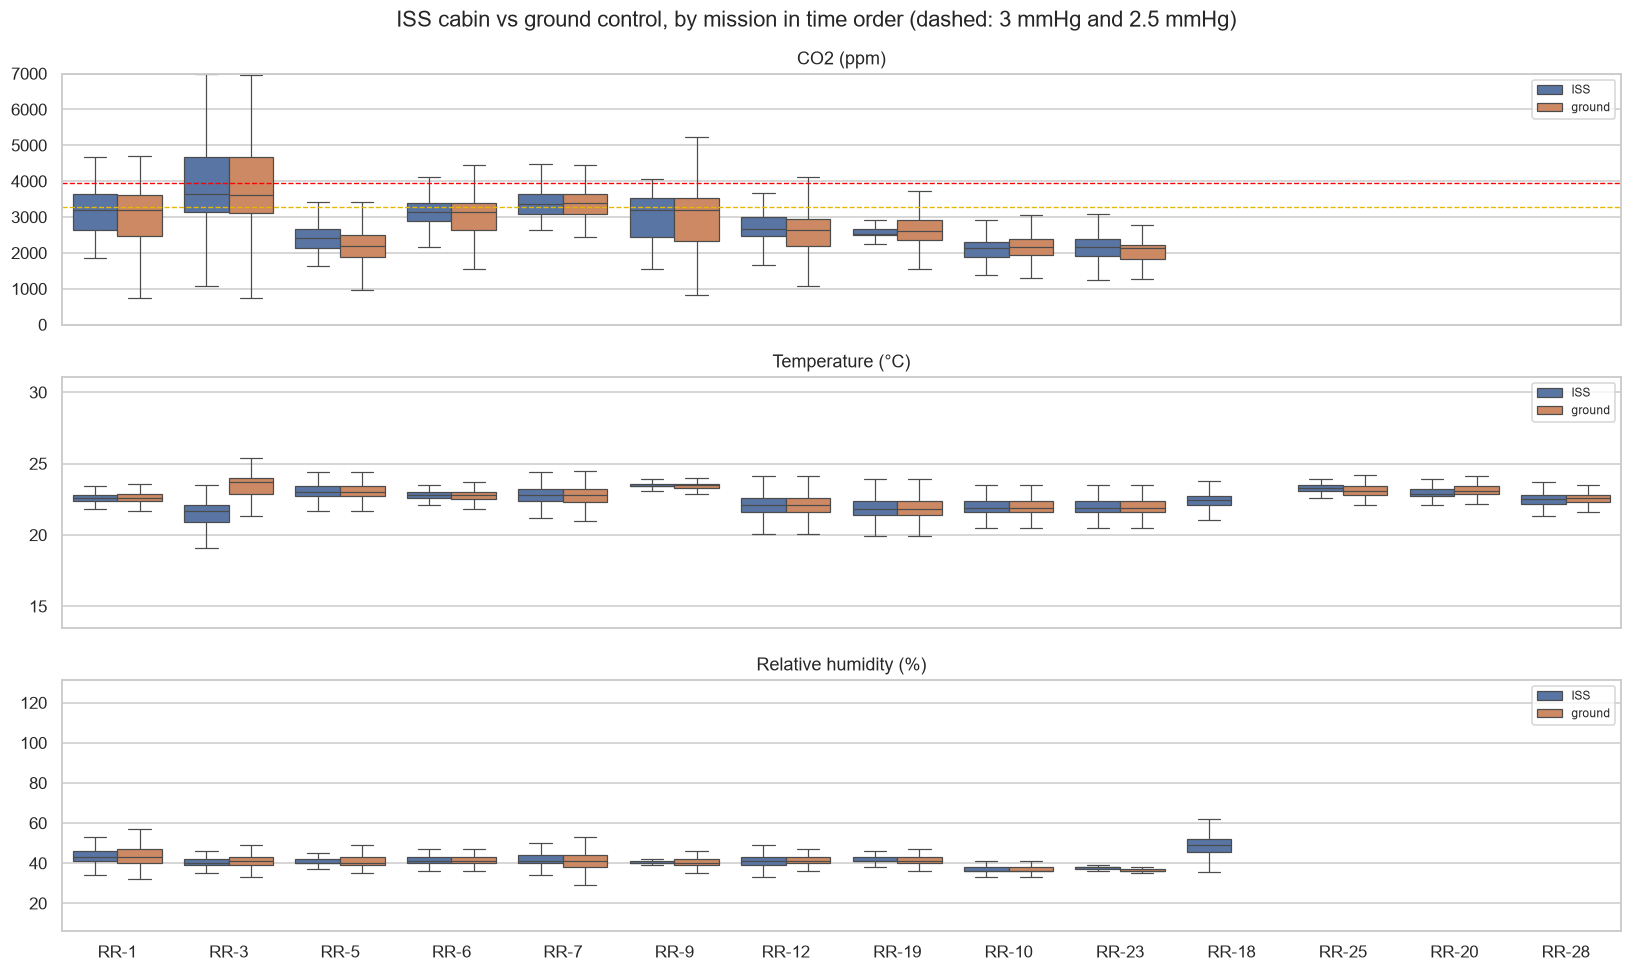

In [4]:
long = pd.concat([
    cabin[["mission", "co2_iss", "temperature_iss", "humidity_iss"]].set_axis(["mission", "co2_ppm", "temperature_c", "humidity_pct"], axis=1).assign(where="ISS"),
    cabin[["mission", "co2_ground", "temperature_ground", "humidity_ground"]].set_axis(["mission", "co2_ppm", "temperature_c", "humidity_pct"], axis=1).assign(where="ground")], ignore_index=True)
order = info.index.tolist()
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for ax, col, title in zip(axes, ["co2_ppm", "temperature_c", "humidity_pct"], ["CO2 (ppm)", "Temperature (°C)", "Relative humidity (%)"]):
    sns.boxplot(data=long, x="mission", y=col, hue="where", order=order, ax=ax, fliersize=0, linewidth=0.8)
    ax.set(title=title, xlabel="", ylabel="")
    ax.legend(loc="upper right", fontsize=8)
axes[0].axhline(3.0 * 1e6 / 760, color="red", ls="--", lw=0.9); axes[0].axhline(2.5 * 1e6 / 760, color="#e6b800", ls="--", lw=0.9)
axes[0].set_ylim(0, 7000)
fig.suptitle("ISS cabin vs ground control, by mission in time order (dashed: 3 mmHg and 2.5 mmHg)")
savefig("06_iss_vs_ground");
long.groupby("where")[["co2_ppm", "temperature_c", "humidity_pct"]].agg(["median", "std", lambda s: s.quantile(.05), lambda s: s.quantile(.95)]).round(1)

## 3. CO2 in time

,hours,mean_mmHg,sd_mmHg,diurnal_peak_to_trough,acf_1h,acf_24h
mission,,,,,,
RR-1,1009,2.43,0.43,0.24,0.99,0.77
RR-3,1200,2.82,1.03,0.46,0.99,0.86
RR-5,1602,1.86,0.35,0.16,0.99,0.85
RR-6,1466,2.22,0.62,0.36,0.99,0.78
RR-7,1842,2.66,1.15,0.41,0.98,0.83
RR-9,841,2.30,0.45,0.20,0.97,0.85
RR-12,984,2.04,0.33,0.40,0.96,0.58
RR-19,851,1.95,0.21,0.35,0.94,0.66
RR-10,639,1.60,0.22,0.49,0.89,0.58


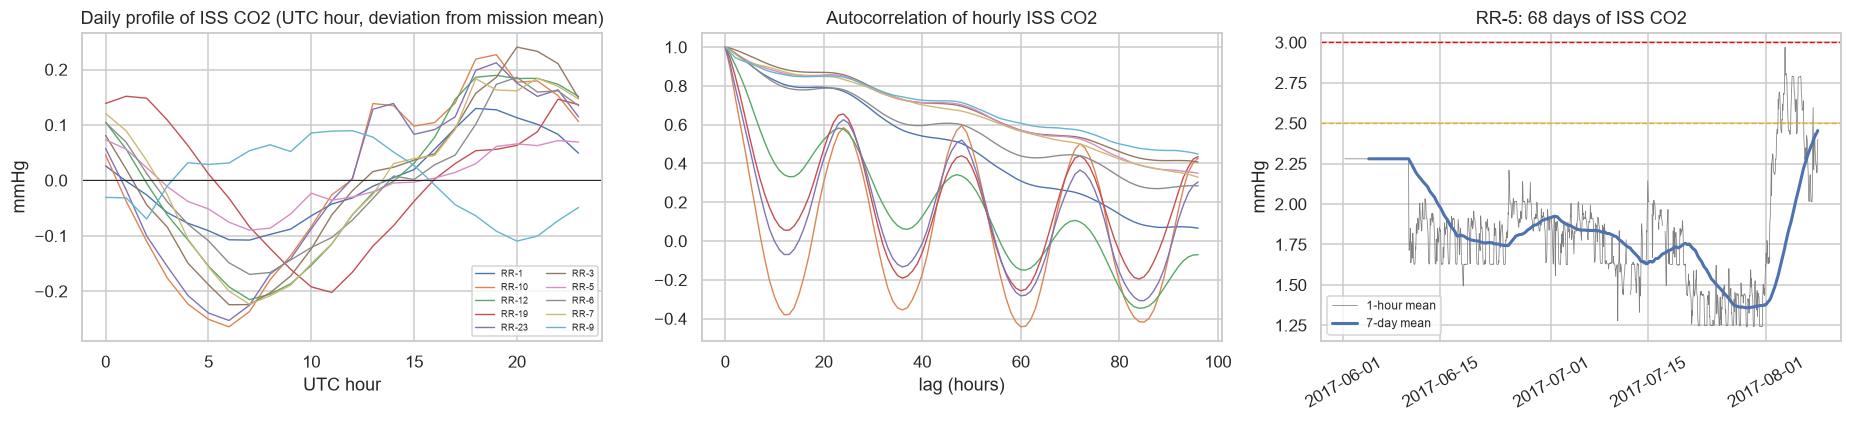

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for mission, g in h.groupby("mission"):
    if g.co2_mmhg.notna().sum() < 24 * 20:
        continue
    prof = g.groupby(g.hour.dt.hour).co2_mmhg.mean()
    axes[0].plot(prof.index, prof - prof.mean(), lw=0.9, label=mission)
    s = g.co2_mmhg.interpolate(limit=6).dropna()
    axes[1].plot(acf(s, nlags=96, fft=True), lw=0.9, label=mission)
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set(title="Daily profile of ISS CO2 (UTC hour, deviation from mission mean)", xlabel="UTC hour", ylabel="mmHg")
axes[0].legend(fontsize=6, ncol=2)
axes[1].set(title="Autocorrelation of hourly ISS CO2", xlabel="lag (hours)")
longest = h[h.mission == "RR-5"]
axes[2].plot(longest.hour, longest.co2_mmhg, lw=0.5, color="grey", label="1-hour mean")
axes[2].plot(longest.hour, gate.rolling_mean(longest.co2_mmhg.to_numpy()), lw=2, label="7-day mean")
axes[2].axhline(3.0, color="red", ls="--", lw=0.9); axes[2].axhline(2.5, color="#e6b800", ls="--", lw=0.9)
axes[2].set(title="RR-5: 68 days of ISS CO2", ylabel="mmHg"); axes[2].tick_params(axis="x", rotation=30); axes[2].legend(fontsize=8)
savefig("06_co2_in_time");

rows = []
for mission, g in h.groupby("mission"):
    s = g.co2_mmhg
    if s.notna().sum() < 100:
        continue
    filled = s.interpolate(limit=6).dropna()
    prof = g.groupby(g.hour.dt.hour).co2_mmhg.mean()
    a = acf(filled, nlags=24, fft=True)
    rows.append({"mission": mission, "hours": int(s.notna().sum()), "mean_mmHg": s.mean(), "sd_mmHg": s.std(),
                 "diurnal_peak_to_trough": prof.max() - prof.min(), "acf_1h": a[1], "acf_24h": a[24]})
time_stats = pd.DataFrame(rows).set_index("mission").loc[[m for m in order if m in h.mission.unique() and m in [r["mission"] for r in rows]]]
time_stats.round(2)

In [6]:
# How often would the NASA limits be exceeded on the real ISS series?
rows = []
for mission, g in h.groupby("mission"):
    one = g.co2_mmhg.to_numpy()
    if np.isfinite(one).sum() < 100:
        continue
    seven = gate.rolling_mean(one)
    rows.append({"mission": mission, "hours": int(np.isfinite(one).sum()),
                 "share_1h_above_3": np.nanmean(one[np.isfinite(one)] > gate.LIMIT_1H_MMHG),
                 "hours_with_7d_mean": int(np.isfinite(seven).sum()),
                 "share_7d_above_2.5": np.nanmean(seven[np.isfinite(seven)] > gate.LIMIT_7D_MMHG) if np.isfinite(seven).any() else np.nan,
                 "share_either": gate.co2_high(one, seven)[np.isfinite(one)].mean(),
                 "max_1h": np.nanmax(one), "max_7d": np.nanmax(seven) if np.isfinite(seven).any() else np.nan})
exceed = pd.DataFrame(rows).set_index("mission").loc[[m for m in order if m in [r["mission"] for r in rows]]]
total = pd.Series({"hours": exceed.hours.sum(), "share_1h_above_3": np.average(exceed.share_1h_above_3, weights=exceed.hours),
                   "share_7d_above_2.5": np.average(exceed["share_7d_above_2.5"].fillna(0), weights=exceed.hours_with_7d_mean),
                   "share_either": np.average(exceed.share_either, weights=exceed.hours)}, name="ALL")
print(total.round(3).to_string())
exceed.round(3)

hours                 11230.000
share_1h_above_3          0.068
share_7d_above_2.5        0.263
share_either              0.254


,hours,share_1h_above_3,hours_with_7d_mean,share_7d_above_2.5,share_either,max_1h,max_7d
mission,,,,,,,
RR-1,1009,0.089,926,0.454,0.437,3.498,2.856
RR-3,1200,0.368,1117,0.728,0.706,5.230,4.183
RR-5,1602,0.000,1557,0.000,0.000,2.971,2.455
RR-6,1466,0.005,1405,0.137,0.121,3.155,2.567
RR-7,1842,0.119,1827,0.558,0.562,6.813,5.556
RR-9,841,0.002,758,0.460,0.417,3.011,2.685
RR-12,984,0.000,901,0.000,0.000,2.734,2.299
RR-19,851,0.000,768,0.000,0.000,2.671,2.110
RR-10,639,0.000,643,0.000,0.000,2.220,1.700


## 4. Temperature, humidity and CO2

In [7]:
rows = []
for mission, g in h.groupby("mission"):
    if g.co2_mmhg.notna().sum() < 24 * 20:
        continue
    c = g[["co2_mmhg", "temperature_iss", "humidity_iss"]].corr(method="spearman")
    rows.append({"mission": mission, "co2~temperature": c.iloc[0, 1], "co2~humidity": c.iloc[0, 2], "temperature~humidity": c.iloc[1, 2]})
rel = pd.DataFrame(rows).set_index("mission")
print("median across missions:", rel.median().round(2).to_dict())
print("ISS temperature: median %.1f °C, 5-95 %% range %.1f to %.1f | humidity: median %.0f %%, range %.0f to %.0f" % (
    hourly.temperature_iss.median(), hourly.temperature_iss.quantile(.05), hourly.temperature_iss.quantile(.95),
    hourly.humidity_iss.median(), hourly.humidity_iss.quantile(.05), hourly.humidity_iss.quantile(.95)))
rel.round(2)

median across missions: {'co2~temperature': -0.09, 'co2~humidity': 0.02, 'temperature~humidity': -0.06}
ISS temperature: median 22.7 °C, 5-95 % range 21.1 to 23.6 | humidity: median 41 %, range 36 to 52


,co2~temperature,co2~humidity,temperature~humidity
mission,,,
RR-1,-0.42,0.51,-0.36
RR-10,-0.11,-0.01,0.15
RR-12,0.00,-0.06,-0.00
RR-19,-0.08,-0.16,0.06
RR-23,-0.05,0.06,-0.30
RR-3,-0.01,-0.15,-0.30
RR-5,-0.08,0.15,0.07
RR-6,-0.24,-0.24,0.10
RR-7,-0.21,0.21,-0.31


## 5. ISS radiation, and how it compares with Mars

ISS: median total 0.292 mGy/day (GCR 0.157 + SAA 0.128); day-to-day SD 0.052
Mars surface (RAD E): median 0.160 mGy/day -> ISS / Mars = 1.82


,start,days,gcr,saa,total,total_sd,saa_share
mission,,,,,,,
RR-1,2014-09-21,39,0.132,0.072,0.203,0.008,0.355
RR-3,2016-04-08,43,0.142,0.085,0.227,0.010,0.377
RR-4,2017-02-24,19,0.157,0.082,0.240,0.007,0.345
RR-9,2017-08-18,32,0.126,0.181,0.313,0.049,0.587
RR-6,2017-12-15,49,0.166,0.116,0.283,0.010,0.408
RR-7,2018-06-29,76,0.175,0.104,0.280,0.026,0.377
RR-8,2018-12-05,40,0.173,0.111,0.285,0.014,0.392
RR-12,2019-04-17,37,0.147,0.210,0.358,0.018,0.588
RR-17,2019-07-25,58,0.158,0.163,0.321,0.017,0.508


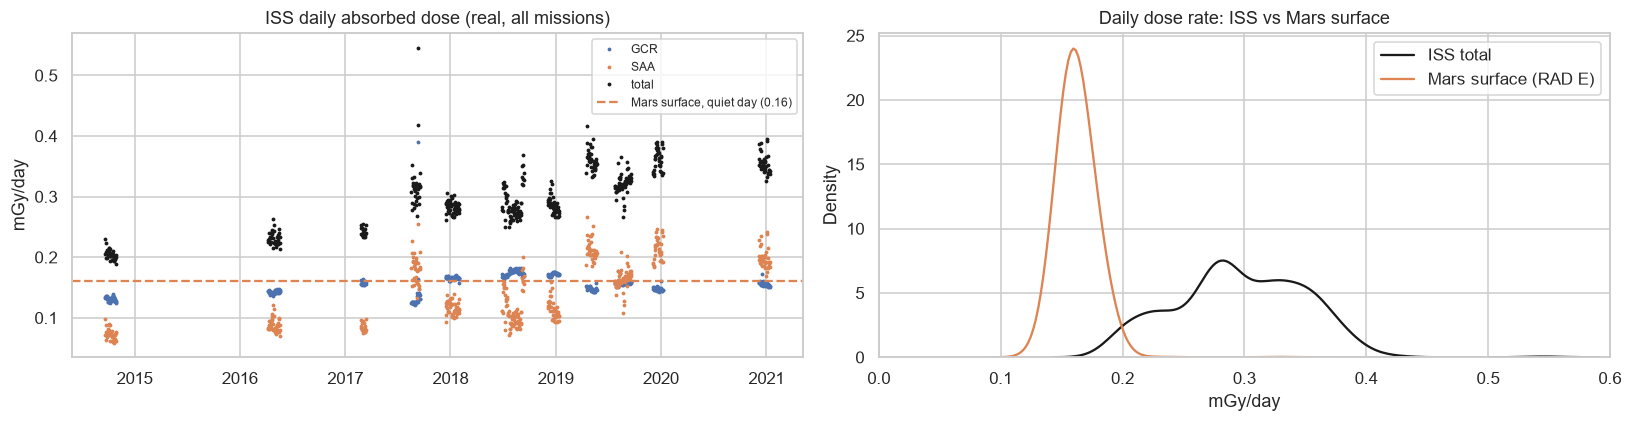

In [8]:
dose["saa_share"] = dose.saa / dose.total
by_mission = dose.groupby("mission").agg(start=("time", "min"), days=("total", "size"), gcr=("gcr", "median"), saa=("saa", "median"),
                                         total=("total", "median"), total_sd=("total", "std"), saa_share=("saa_share", "median")).sort_values("start")
mars = pd.read_parquet(PROCESSED / "msl_rad_daily.parquet")
mars_quiet = mars.dose_e.median() / 1000
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(dose.time, dose.gcr, ".", ms=3, label="GCR")
axes[0].plot(dose.time, dose.saa, ".", ms=3, label="SAA")
axes[0].plot(dose.time, dose.total, ".", ms=3, color="k", label="total")
axes[0].axhline(mars_quiet, color="#dd8452", ls="--", label=f"Mars surface, quiet day ({mars_quiet:.2f})")
axes[0].set(title="ISS daily absorbed dose (real, all missions)", ylabel="mGy/day"); axes[0].legend(fontsize=8)
sns.kdeplot(dose.total, ax=axes[1], label="ISS total", color="k"); sns.kdeplot(mars.dose_e / 1000, ax=axes[1], label="Mars surface (RAD E)", color="#dd8452", clip=(0, 0.5))
axes[1].set(title="Daily dose rate: ISS vs Mars surface", xlabel="mGy/day", xlim=(0, 0.6)); axes[1].legend()
savefig("06_iss_radiation");
print("ISS: median total %.3f mGy/day (GCR %.3f + SAA %.3f); day-to-day SD %.3f" % (dose.total.median(), dose.gcr.median(), dose.saa.median(), dose.total.std()))
print("Mars surface (RAD E): median %.3f mGy/day -> ISS / Mars = %.2f" % (mars_quiet, dose.total.median() / mars_quiet))
by_mission.round(3)

## Findings

1. **CO2 is in ppm; sampling is every 5 minutes (2014–2019 missions) or every minute (2020 onward).** Converted with `mmHg = ppm × 760 / 1e6`.
   Both facts are now in `docs/DATASETS.md`.
2. **Only 10 of the 14 missions have ISS CO2: 468 days in total, 35–82 days each.** The four newest and longest missions (RR-18, RR-20, RR-25, RR-28) have temperature and humidity only.
3. **The "ground" column is not Earth air.** Ground CO2 follows the ISS value (medians within a few ppm of each other in most missions),
   because the ground-control habitat replays the ISS environment. The planned "ISS vs ground" contrast therefore says little; the useful contrast is between missions and over time.
4. **ISS CO2 has come down over the years.** Mission means fell from 2.4–2.8 mmHg (2014–2018) to 1.6 mmHg (2020–21).
5. **CO2 changes slowly.** Hour-to-hour autocorrelation is 0.89–0.99 and still 0.6–0.9 after 24 hours: the level wanders over days, it does not jitter.
   The daily cycle is small (0.2–0.5 mmHg peak to trough) next to those slow swings (SD 0.2–1.2 mmHg).
6. **The team's limits are exceeded often on the older missions and never on the recent ones.** Over all 468 days the 1-hour mean is above 3 mmHg 6.8 % of the time
   and the 7-day mean is above 2.5 mmHg 26 % of the time. RR-3 (2016) spent 73 % of its time above the 7-day limit; RR-5, RR-12, RR-19, RR-10 and RR-23 spent none.
7. **Temperature and humidity are tightly controlled and unrelated to CO2**: 22.7 °C (5–95 % range 21.1–23.6), 41 % humidity (36–52);
   median within-mission correlation with CO2 is −0.09 and 0.02. They are context, not predictors.
8. **ISS radiation: 0.29 mGy/day, about 1.8 times the Mars surface** (0.16 mGy/day in RAD's detector E). GCR contributes 0.16 and the South Atlantic Anomaly 0.13 mGy/day;
   the SAA share ranges from 35 % to 59 % between missions (it depends on station altitude). Day-to-day SD is 0.05 mGy/day.
   11 missions have radiation, 467 days. Mars has no SAA and a thin atmosphere overhead, so its quiet dose is lower but a solar storm reaches the ground (notebook 04).

## Decision

- **Use the hourly table `iss_cabin.parquet`** for the gate and the generator (rolling 1-hour and 7-day means; hours without data stay missing).
- **Notebook 07 must report the gate separately for the older (2014–2019) and the recent (2020–21) missions**, because the answer to
  "how often would it fire" is 0 % or more than 50 % depending on the era.
- **ISS-mode radiation uses the `total` column** (GCR + SAA) and the dose counter sums it itself; there is no accumulated column in the API tables.

**Data quirks to keep in mind**
- RR-9's telemetry is dated August–September 2018 while its radiation table is dated August–September 2017 (RR-9 flew in 2017). The telemetry year looks mislabelled at the source. Nothing here depends on the calendar year of RR-9, so it is left as delivered.
- RR-7 has CO2 on about half of its rows and RR-10/RR-23 on 83–88 %; hourly means hide this, but the 7-day mean needs at least half the hours.

**Known limits:** CO2 here is measured for a rodent habitat's location in the cabin, not at a crewmember's face; local pockets around a sleeping astronaut can be higher.
Ten short missions are a thin sample of seven years of station operations.